# INCLUDE preprocessing

This notebook loads INCLUDE for Italian, Spanish, Russian, Chinese, and Hindi; cleans and deduplicates the MCQ records; maps `regional_feature` into our `regionality` labels; explores the distribution; and saves SFT-compatible JSONL files under `multilingual/data/processed/include/`.

# Imports

In [1]:
from pathlib import Path
import json
import os

import pandas as pd
!pip install matplotlib
import matplotlib.pyplot as plt
from datasets import load_dataset

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 4.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.7/118.7 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 107.9 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 362.6/362.6 kB 333.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 171.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 262.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.8/122.8 kB 325.1 MB/s eta 0:00:00


In [15]:
REPO_ROOT = Path('/scratch/workspace/emma/standard-project-m2-mystery-machine')
OUTPUT_DIR = REPO_ROOT / 'multilingual/data/processed/include'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_NAME = 'CohereLabs/include-base-44'
LANGUAGE_CONFIGS = {
    'italian': 'Italian',
    'spanish': 'Spanish',
    'russian': 'Russian',
    'chinese': 'Chinese',
    'hindi': 'Hindi',
}
SPLITS = ['validation', 'test']
ANSWER_MAP = {0: 'A', 1: 'B', 2: 'C', 3: 'D', '0': 'A', '1': 'B', '2': 'C', '3': 'D'}
REGIONALITY_MAP = {
    "culture": "regional",
    "culture-related": "regional",
    "region explicit": "regional",
    "region-explicit": "regional",
    "region implicit": "regional_implicit",
    "region-implicit": "regional_implicit",
    "agnostic": "region_agnostic",
}
VALID_ANSWERS = {'A', 'B', 'C', 'D'}
VALID_REGIONALITIES = {'regional', 'regional_implicit', 'region_agnostic'}
HF_TOKEN = os.environ.get('HF_TOKEN')

## Load all languages and splits

In [16]:
frames = []

for language, config in LANGUAGE_CONFIGS.items():
    for split in SPLITS:
        print(f'Loading {DATASET_NAME} | config={config} | split={split}')
        ds = load_dataset(DATASET_NAME, config, split=split, token=HF_TOKEN)
        df_split = ds.to_pandas()
        df_split['language'] = language
        df_split['source_split'] = split
        df_split['source_idx'] = range(len(df_split))
        frames.append(df_split)

df_raw = pd.concat(frames, ignore_index=True)
print(f'Loaded rows: {len(df_raw)}')
display(df_raw.head())

Loading CohereLabs/include-base-44 | config=Italian | split=validation
Loading CohereLabs/include-base-44 | config=Italian | split=test
Loading CohereLabs/include-base-44 | config=Spanish | split=validation
Loading CohereLabs/include-base-44 | config=Spanish | split=test
Loading CohereLabs/include-base-44 | config=Russian | split=validation
Loading CohereLabs/include-base-44 | config=Russian | split=test
Loading CohereLabs/include-base-44 | config=Chinese | split=validation
Loading CohereLabs/include-base-44 | config=Chinese | split=test
Loading CohereLabs/include-base-44 | config=Hindi | split=validation
Loading CohereLabs/include-base-44 | config=Hindi | split=test
Loaded rows: 2912


,language,country,domain,subject,regional_feature,level,question,option_a,option_b,option_c,option_d,answer,source_split,source_idx
0,italian,Italian,STEM,Biology,agnostic,university,-46) Quali tra i seguenti composti possono ess...,amminoacidi e monosaccaridi,amminoacidi e acidi grassi,amminoacidi e nucleotidi,C- amminoacidi e glicogeno,0,validation,0
1,italian,NaN,STEM,CS,agnostic,12,Cosa usano le stampanti a matrice per stampare...,cartuccia con inchiostro,nastro inchiostrato,cartuccia con tonner,cartuccia con polvere d’inchiostro,1,validation,1
2,italian,Italian,STEM,Biology,agnostic,university,-31) II DNA è formato da:,due filamenti polinucleotidici avvolti ad elica,un filamento polinucleotidico,due filamenti di amminoacidi avvolti ad elica,una sequenza semplice di aminoacidi,0,validation,2
3,italian,Italian,STEM,Biology,agnostic,university,186. Una cellula umana che contiene 22 autosom...,una cellula uovo,uno spermatozoo,uno zigote,una cellula somatica di un individuo di sesso ...,1,validation,3
4,italian,Italy,STEM,Physics,agnostic,High School,"Considerati quattro condensatori C1, C2 rispet...","29,8 mF","8,8 mF","24,8 mF",45 mF,0,validation,4


# Exploration

In [17]:
print("Columns:")
print(df_raw.columns.tolist())

print("\nShape:")
print(df_raw.shape)

print("\nRegional feature values:")
display(df_raw["regional_feature"].value_counts(dropna=False).to_frame("n_examples"))

print("\nLanguages:")
display(df_raw["language"].value_counts().sort_index().to_frame("n_examples"))

print("\nSource splits:")
display(df_raw["source_split"].value_counts().sort_index().to_frame("n_examples"))

print("\nDomains:")
display(df_raw["domain"].value_counts(dropna=False).sort_index().to_frame("n_examples"))

print("\nSubjects, top 30:")
display(df_raw["subject"].value_counts(dropna=False).head(30).to_frame("n_examples"))

print("\nLevels:")
display(df_raw["level"].value_counts(dropna=False).sort_index().to_frame("n_examples"))

Columns:
['language', 'country', 'domain', 'subject', 'regional_feature', 'level', 'question', 'option_a', 'option_b', 'option_c', 'option_d', 'answer', 'source_split', 'source_idx']

Shape:
(2912, 14)

Regional feature values:


,n_examples
regional_feature,
region implicit,1331
region explicit,1098
agnostic,293
culture,190



Languages:


,n_examples
language,
chinese,585
hindi,587
italian,578
russian,592
spanish,570



Source splits:


...

,n_examples
domain,
Applied Science,266
Arts & Humanities,694
Business & Commerce,150
Driving License,170
General knowledge,76
Health oriented education,305
Marine License,69
Other,35
Professional certification,297



Subjects, top 30:


,n_examples
subject,
Professional certification,312
Medicine,281
Geography,229
Driving License,185
Law,169
Education,164
Economics,163
History,159
Sociology,122



Levels:


,n_examples
level,
,40
12,8
Academic,2316
High School,2
Professional,432
Professional exam,1
University,12
bachelor,33
competitive_exam,12


In [18]:
# Map INCLUDE regional_feature to our regionality labels

df = df_raw.copy()
df["regional_feature"] = df["regional_feature"].astype(str).str.strip()
df["regionality"] = df["regional_feature"].map(REGIONALITY_MAP)
unknown_features = sorted(df.loc[df["regionality"].isna(), "regional_feature"].dropna().unique())
print("Unknown regional_feature values:")
print(unknown_features)

assert df["regionality"].notna().all(), "Some regional_feature values were not mapped."
display(
    df.groupby(["language", "regional_feature", "regionality"])
    .size()
    .reset_index(name="n_examples")
    .sort_values(["language", "regionality", "regional_feature"])
)

Unknown regional_feature values:
[]


,language,regional_feature,regionality,n_examples
0,chinese,agnostic,region_agnostic,54
1,chinese,culture,regional,58
2,chinese,region explicit,regional,224
3,chinese,region implicit,regional_implicit,249
4,hindi,agnostic,region_agnostic,59
5,hindi,culture,regional,41
6,hindi,region explicit,regional,231
7,hindi,region implicit,regional_implicit,256
8,italian,agnostic,region_agnostic,60
9,italian,culture,regional,22


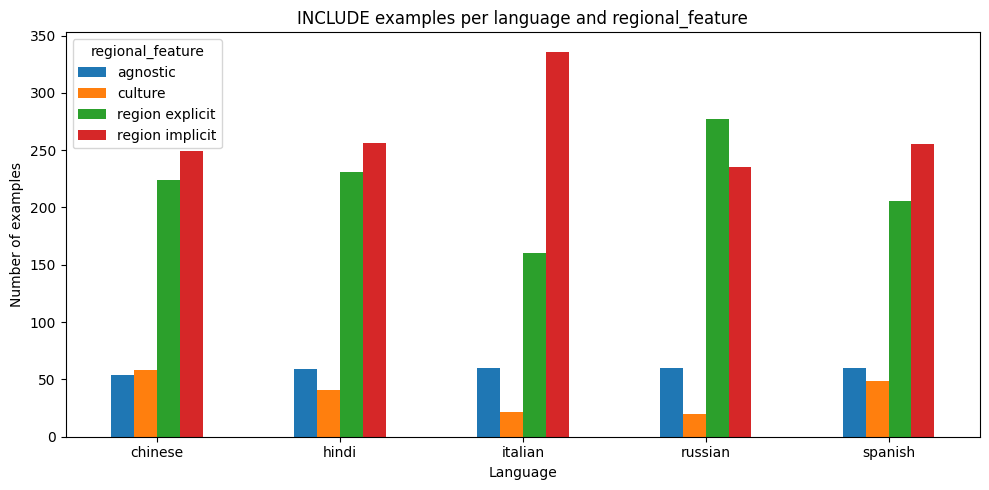

In [19]:
plot_df = pd.crosstab(df_raw['language'], df_raw['regional_feature'], dropna=False)
ax = plot_df.plot(kind='bar', figsize=(10, 5))
ax.set_title('INCLUDE examples per language and regional_feature')
ax.set_xlabel('Language')
ax.set_ylabel('Number of examples')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Clean and map labels

In [24]:
def clean_text(x):
    if pd.isna(x):
        return ""
    return str(x).strip()


def map_answer(x):
    if pd.isna(x):
        return ""
    if x in ANSWER_MAP:
        return ANSWER_MAP[x]
    x_str = str(x).strip()
    return ANSWER_MAP.get(x_str, x_str.upper())


def make_prompt(row):
    return (
        f"{clean_text(row['question'])}\n\n"
        f"A) {clean_text(row['A'])}\n"
        f"B) {clean_text(row['B'])}\n"
        f"C) {clean_text(row['C'])}\n"
        f"D) {clean_text(row['D'])}"
    )

def safe_id_part(x):
    return clean_text(x).replace(" ", "_").replace("/", "_").replace("\\", "_")


def write_jsonl(records, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")


def read_jsonl(path):
    loaded = []
    with path.open("r", encoding="utf-8") as f:
        for line in f:
            loaded.append(json.loads(line))
    return loaded

In [25]:
df = df_raw.copy()

df["question"] = df["question"].apply(clean_text)
df["option_a"] = df["option_a"].apply(clean_text)
df["option_b"] = df["option_b"].apply(clean_text)
df["option_c"] = df["option_c"].apply(clean_text)
df["option_d"] = df["option_d"].apply(clean_text)

df["answer"] = df["answer"].apply(map_answer)
df["regional_feature"] = df["regional_feature"].apply(clean_text)
df["regionality"] = df["regional_feature"].map(REGIONALITY_MAP)

unknown_regional_features = sorted(df.loc[df["regionality"].isna(), "regional_feature"].dropna().unique())
print("Unknown regional_feature values:", unknown_regional_features)
assert df["regionality"].notna().all()

n_before = len(df)

df = df[
    df["question"].ne("")
    & df["option_a"].ne("")
    & df["option_b"].ne("")
    & df["option_c"].ne("")
    & df["option_d"].ne("")
].copy()

df = df.rename(columns={
    "option_a": "A",
    "option_b": "B",
    "option_c": "C",
    "option_d": "D",
})

df = df[df["answer"].isin(VALID_ANSWERS)].copy()

dedup_cols = ["language", "question", "A", "B", "C", "D"]
n_before_dedup = len(df)
df = df.drop_duplicates(subset=dedup_cols).reset_index(drop=True)

n_after_cleaning = len(df)

print(f"Rows before cleaning:       {n_before}")
print(f"Rows before deduplication:  {n_before_dedup}")
print(f"Rows after deduplication:   {n_after_cleaning}")
print(f"Removed total:              {n_before - n_after_cleaning}")

display(df.head())

Unknown regional_feature values: []
Rows before cleaning:       2912
Rows before deduplication:  2912
Rows after deduplication:   2899
Removed total:              13


,language,country,domain,subject,regional_feature,level,question,A,B,C,D,answer,source_split,source_idx,regionality
0,italian,Italian,STEM,Biology,agnostic,university,-46) Quali tra i seguenti composti possono ess...,amminoacidi e monosaccaridi,amminoacidi e acidi grassi,amminoacidi e nucleotidi,C- amminoacidi e glicogeno,A,validation,0,region_agnostic
1,italian,NaN,STEM,CS,agnostic,12,Cosa usano le stampanti a matrice per stampare...,cartuccia con inchiostro,nastro inchiostrato,cartuccia con tonner,cartuccia con polvere d’inchiostro,B,validation,1,region_agnostic
2,italian,Italian,STEM,Biology,agnostic,university,-31) II DNA è formato da:,due filamenti polinucleotidici avvolti ad elica,un filamento polinucleotidico,due filamenti di amminoacidi avvolti ad elica,una sequenza semplice di aminoacidi,A,validation,2,region_agnostic
3,italian,Italian,STEM,Biology,agnostic,university,186. Una cellula umana che contiene 22 autosom...,una cellula uovo,uno spermatozoo,uno zigote,una cellula somatica di un individuo di sesso ...,B,validation,3,region_agnostic
4,italian,Italy,STEM,Physics,agnostic,High School,"Considerati quattro condensatori C1, C2 rispet...","29,8 mF","8,8 mF","24,8 mF",45 mF,A,validation,4,region_agnostic


## Explore after cleaning

In [26]:
print("Counts by language:")
display(df["language"].value_counts().sort_index().to_frame("n_examples"))

print("\nCounts by regionality:")
display(df["regionality"].value_counts().sort_index().to_frame("n_examples"))

print("\nCounts by language and regionality:")
display(
    df.groupby(["language", "regionality"])
    .size()
    .reset_index(name="n_examples")
    .pivot(index="language", columns="regionality", values="n_examples")
    .fillna(0)
    .astype(int)
)

print("\nCounts by source split:")
display(df["source_split"].value_counts().sort_index().to_frame("n_examples"))

print("\nCounts by language and source split:")
display(
    df.groupby(["language", "source_split"])
    .size()
    .reset_index(name="n_examples")
    .pivot(index="language", columns="source_split", values="n_examples")
    .fillna(0)
    .astype(int)
)

print("\nCounts by domain:")
display(df["domain"].value_counts(dropna=False).sort_index().to_frame("n_examples"))

print("\nCounts by language and domain:")
display(df.groupby(["language", "domain"]).size().reset_index(name="n_examples"))

Counts by language:


,n_examples
language,
chinese,584
hindi,584
italian,575
russian,586
spanish,570



Counts by regionality:


,n_examples
regionality,
region_agnostic,291
regional,1282
regional_implicit,1326



Counts by language and regionality:


...

source_split,test,validation
language,,
chinese,544,40
hindi,544,40
italian,545,30
russian,546,40
spanish,550,20



Counts by domain:


,n_examples
domain,
Applied Science,264
Arts & Humanities,692
Business & Commerce,149
Driving License,165
General knowledge,76
Health oriented education,303
Marine License,69
Other,35
Professional certification,297



Counts by language and domain:


,language,domain,n_examples
0,chinese,Applied Science,76
1,chinese,Arts & Humanities,92
2,chinese,Business & Commerce,76
3,chinese,Driving License,71
4,chinese,Health oriented education,91
5,chinese,Other,10
6,chinese,Professional certification,71
7,chinese,STEM,21
8,chinese,Social Science,76
9,hindi,Applied Science,76


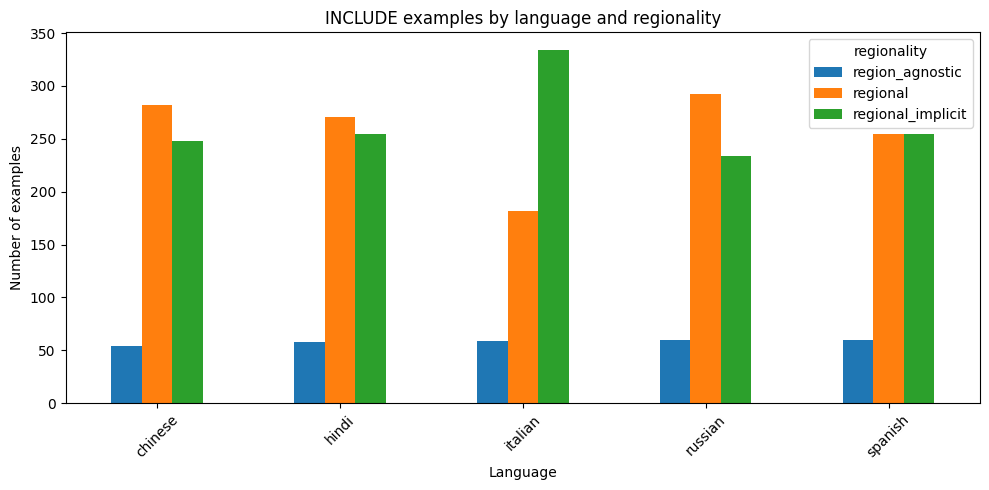

In [27]:
plot_df = (
    df.groupby(["language", "regionality"])
    .size()
    .reset_index(name="n_examples")
    .pivot(index="language", columns="regionality", values="n_examples")
    .fillna(0)
)

ax = plot_df.plot(kind="bar", figsize=(10, 5))
ax.set_title("INCLUDE examples by language and regionality")
ax.set_xlabel("Language")
ax.set_ylabel("Number of examples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
print("Total by language:")
display(df.groupby("language").size().reset_index(name="n_examples"))

print("\nTotal by regionality:")
display(df.groupby("regionality").size().reset_index(name="n_examples"))

print("\nLanguage × regionality:")
display(
    df.groupby(["language", "regionality"])
    .size()
    .reset_index(name="n_examples")
    .pivot(index="language", columns="regionality", values="n_examples")
    .fillna(0)
    .astype(int)
)

Total by language:


,language,n_examples
0,chinese,584
1,hindi,584
2,italian,575
3,russian,586
4,spanish,570



Total by regionality:


,regionality,n_examples
0,region_agnostic,291
1,regional,1282
2,regional_implicit,1326



Language × regionality:


regionality,region_agnostic,regional,regional_implicit
language,,,
chinese,54,282,248
hindi,58,271,255
italian,59,182,334
russian,60,292,234
spanish,60,255,255


# Convert to SFT-compatible records

In [29]:
def make_record(row, idx):
    source_split = safe_id_part(row["source_split"])
    source_idx = int(row["source_idx"])

    return {
        "id": f"include_{row['language']}_all_{source_split}_{source_idx}",
        "dataset": "include",
        "language": row["language"],
        "split": "all",
        "task_type": "mcq",
        "prompt": make_prompt(row),
        "answer": row["answer"],
        "metadata": {
            "country": clean_text(row.get("country", "")),
            "domain": clean_text(row.get("domain", "")),
            "subject": clean_text(row.get("subject", "")),
            "level": clean_text(row.get("level", "")),
            "regional_feature": clean_text(row.get("regional_feature", "")),
            "regionality": row["regionality"],
            "source_split": row["source_split"],
            "source_idx": source_idx,
        },
    }


records = [make_record(row, idx) for idx, row in df.iterrows()]

print(f"Built records: {len(records)}")
print(json.dumps(records[0], ensure_ascii=False, indent=2))

Built records: 2899
{
  "id": "include_italian_all_validation_0",
  "dataset": "include",
  "language": "italian",
  "split": "all",
  "task_type": "mcq",
  "prompt": "-46) Quali tra i seguenti composti possono essere generati dall'idrolisi di una glicoproteina?\n\nA) amminoacidi e monosaccaridi\nB) amminoacidi e acidi grassi\nC) amminoacidi e nucleotidi\nD) C- amminoacidi e glicogeno",
  "answer": "A",
  "metadata": {
    "country": "Italian",
    "domain": "STEM",
    "subject": "Biology",
    "level": "university",
    "regional_feature": "agnostic",
    "regionality": "region_agnostic",
    "source_split": "validation",
    "source_idx": 0
  }
}


In [ ]:
def safe_id_part(x):
    return str(x).strip().replace(' ', '_').replace('/', '_')


def make_record(row, idx):
    source_split = safe_id_part(row['source_split'])
    source_idx = int(row['source_idx'])
    language = row['language']
    return {
        'id': f'include_{language}_all_{source_split}_{source_idx}',
        'dataset': 'include',
        'language': language,
        'split': 'all',
        'task_type': 'mcq',
        'prompt': make_prompt(row),
        'answer': row['answer'],
        'metadata': {
            'country': clean_text(row.get('country', '')),
            'domain': clean_text(row.get('domain', '')),
            'subject': clean_text(row.get('subject', '')),
            'level': clean_text(row.get('level', '')),
            'regional_feature': clean_text(row.get('regional_feature', '')),
            'regionality': row['regionality'],
            'source_split': row['source_split'],
            'source_idx': source_idx,
        },
    }


records = [make_record(row, idx) for idx, row in df.iterrows()]
print(f'Built records: {len(records)}')
records[0]

In [30]:
def validate_record(record):
    assert record["dataset"] == "include"
    assert record["language"] in LANGUAGE_CONFIGS
    assert record["split"] == "all"
    assert record["task_type"] == "mcq"
    assert record["answer"] in VALID_ANSWERS
    assert record["metadata"]["regionality"] in VALID_REGIONALITIES
    assert "\n\nA) " in record["prompt"]
    assert "\nB) " in record["prompt"]
    assert "\nC) " in record["prompt"]
    assert "\nD) " in record["prompt"]
    assert record["prompt"].strip()
    assert isinstance(record["metadata"]["source_idx"], int)


for record in records:
    validate_record(record)

print("All in-memory records are valid.")

All in-memory records are valid.


# Save

In [32]:
records_by_language = {}

for language in LANGUAGE_CONFIGS:
    language_records = [
        record for record in records
        if record["language"] == language
    ]
    records_by_language[language] = language_records

    all_path = OUTPUT_DIR / f"include_{language}_all.jsonl"
    write_jsonl(language_records, all_path)
    print(f"Saved {len(language_records)} records to:")
    print(all_path)

Saved 575 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/include/include_italian_all.jsonl
Saved 570 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/include/include_spanish_all.jsonl
Saved 586 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/include/include_russian_all.jsonl
Saved 584 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/include/include_chinese_all.jsonl
Saved 584 records to:
/scratch/workspace/emma/standard-project-m2-mystery-machine/multilingual/data/processed/include/include_hindi_all.jsonl


In [33]:
saved_paths = sorted(OUTPUT_DIR.glob("include_*_all.jsonl"))
print(f"Saved JSONL files: {len(saved_paths)}")

for path in saved_paths:
    loaded = read_jsonl(path)
    print(f"{path.name}: {len(loaded)}")

    seen_ids = set()
    seen_prompts = set()

    for record in loaded:
        validate_record(record)

        assert record["id"] not in seen_ids
        seen_ids.add(record["id"])

        prompt_key = (record["language"], record["prompt"])
        assert prompt_key not in seen_prompts
        seen_prompts.add(prompt_key)

print("All saved INCLUDE all-files are valid.")

Saved JSONL files: 5
include_chinese_all.jsonl: 584
include_hindi_all.jsonl: 584
include_italian_all.jsonl: 575
include_russian_all.jsonl: 586
include_spanish_all.jsonl: 570
All saved INCLUDE all-files are valid.
